# 01 - Exploratory Data Analysis

Notebook ini mengisi **Bab 3 (EDA)** laporan:
- a. Distribusi label/kelas
- e. Contoh sampel per kelas
- f. Temuan penting yang memengaruhi preprocessing

Sebelum menjalankan: `python src/make_splits.py` (membuat `data/plantvillage.csv` dan `data/taiwan.csv`).
Semua gambar disimpan ke `outputs/eda/` untuk dimasukkan ke laporan.

In [2]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

from config import DATA_DIR, DATASET_DIR, OUTPUT_DIR, SEED, SHARED_LABELS

EDA_DIR = OUTPUT_DIR / "eda"
EDA_DIR.mkdir(parents=True, exist_ok=True)

pv = pd.read_csv(DATA_DIR / "plantvillage.csv")
tw = pd.read_csv(DATA_DIR / "taiwan.csv")
print("PlantVillage:", len(pv), "gambar,", pv.label.nunique(), "kelas")
print("Taiwan      :", len(tw), "gambar,", tw.label.nunique(), "kelas")
print("Kelas yang sama di kedua dataset:", SHARED_LABELS)

PlantVillage: 14521 gambar, 10 kelas
Taiwan      : 622 gambar, 6 kelas
Kelas yang sama di kedua dataset: ['bacterial_spot', 'healthy', 'late_blight']


## 3a. Distribusi kelas

In [3]:
def split_table(df):
    t = df.pivot_table(index="label", columns="split", values="path", aggfunc="count", fill_value=0)
    t = t[["train", "val", "test"]]
    t["total"] = t.sum(axis=1)
    t["persen"] = (100 * t["total"] / t["total"].sum()).round(1)
    return t.sort_values("total", ascending=False)

for name, df in (("PlantVillage", pv), ("Taiwan", tw)):
    t = split_table(df)
    print(f"\n{name}  (rasio kelas terbesar : terkecil = {t.total.max() / t.total.min():.1f} : 1)")
    display(t)


PlantVillage  (rasio kelas terbesar : terkecil = 14.3 : 1)


split,train,val,test,total,persen
label,,,,,
yellow_leaf_curl_virus,3000,643,643,4286,29.5
bacterial_spot,1191,255,256,1702,11.7
late_blight,1066,228,229,1523,10.5
septoria_leaf_spot,992,213,212,1417,9.8
spider_mite,939,201,201,1341,9.2
healthy,887,190,190,1267,8.7
target_spot,787,169,168,1124,7.7
early_blight,560,120,120,800,5.5
leaf_mold,533,114,115,762,5.2



Taiwan  (rasio kelas terbesar : terkecil = 2.3 : 1)


split,train,val,test,total,persen
label,,,,,
powdery_mildew,106,19,32,157,25.2
bacterial_spot,75,13,22,110,17.7
healthy,71,13,22,106,17.0
late_blight,66,12,20,98,15.8
gray_spot,57,10,17,84,13.5
black_mold,45,8,14,67,10.8


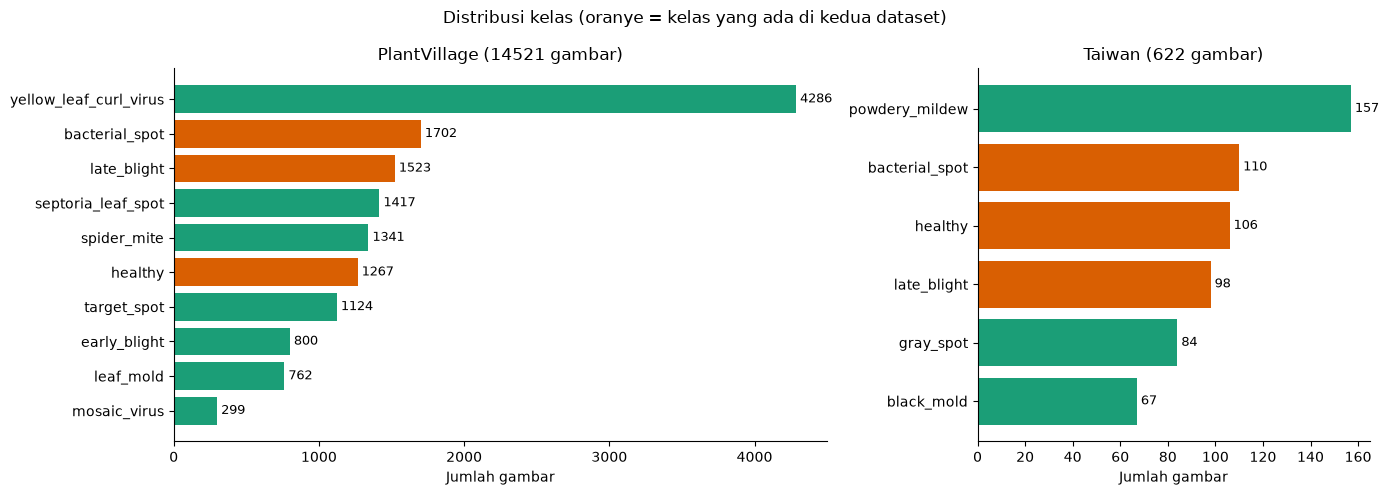

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [10, 6]})
for ax, (name, df) in zip(axes, (("PlantVillage", pv), ("Taiwan", tw))):
    counts = df.label.value_counts()
    colors = ["#d95f02" if lbl in SHARED_LABELS else "#1b9e77" for lbl in counts.index]
    ax.barh(counts.index[::-1], counts.values[::-1], color=colors[::-1])
    for i, v in enumerate(counts.values[::-1]):
        ax.text(v, i, f" {v}", va="center", fontsize=9)
    ax.set_title(f"{name} ({len(df)} gambar)")
    ax.set_xlabel("Jumlah gambar")
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Distribusi kelas (oranye = kelas yang ada di kedua dataset)")
fig.tight_layout()
fig.savefig(EDA_DIR / "distribusi_kelas.png", dpi=150, bbox_inches="tight")
plt.show()

## 3e. Contoh sampel per kelas

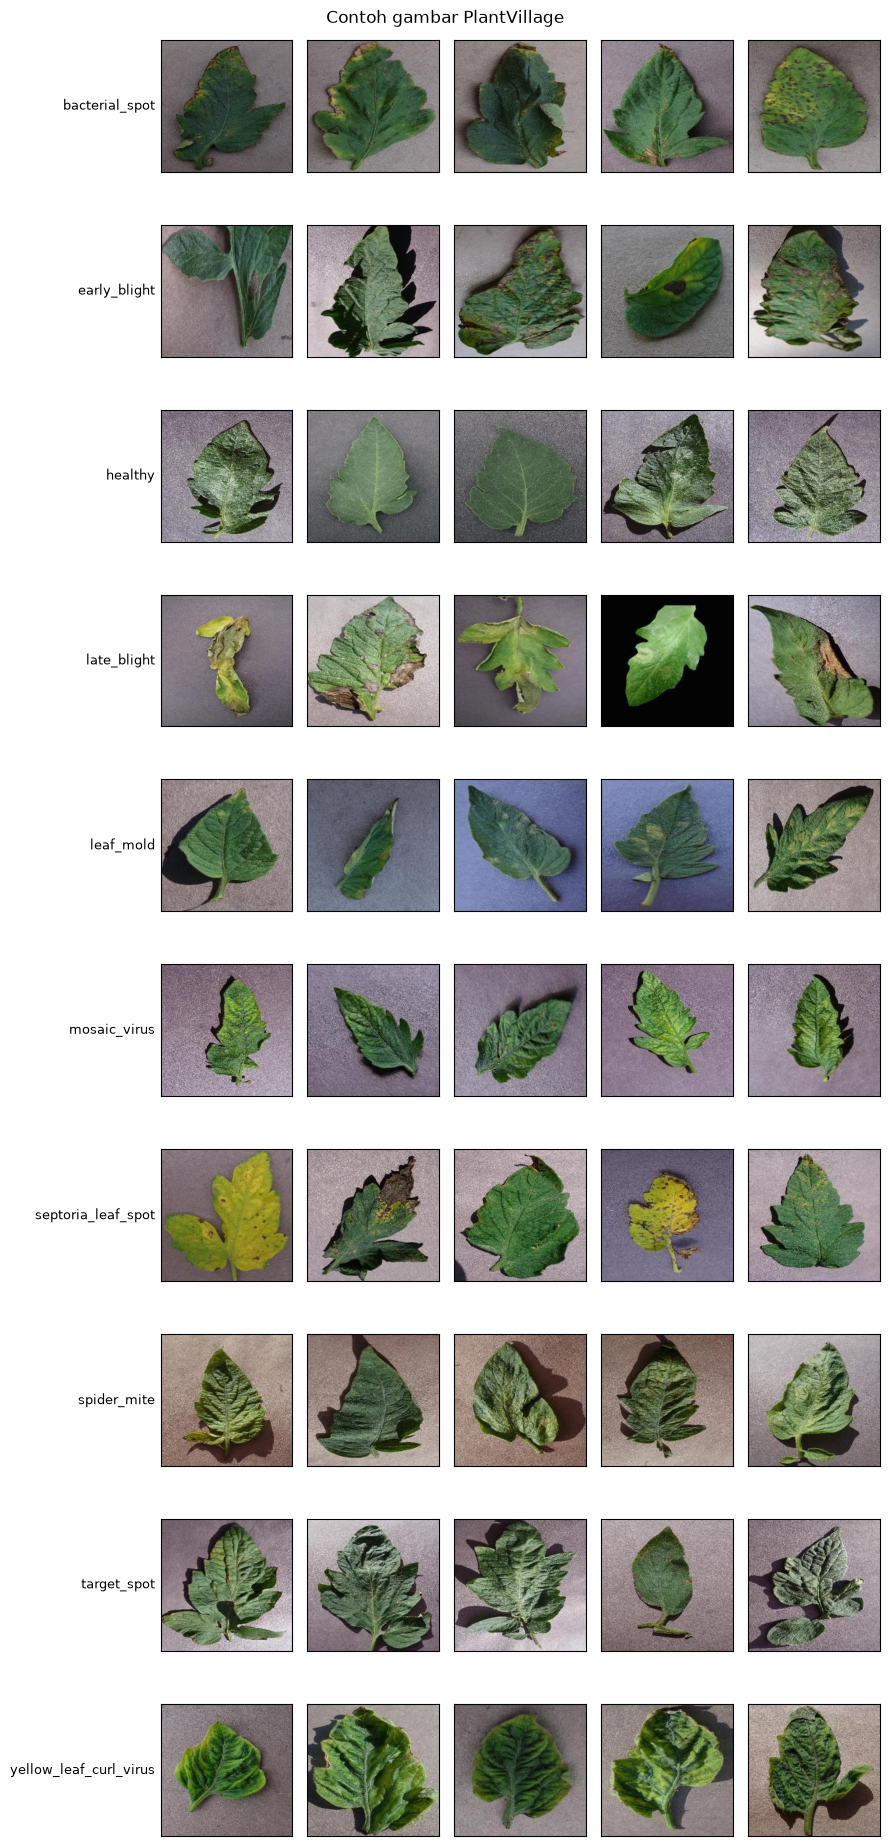

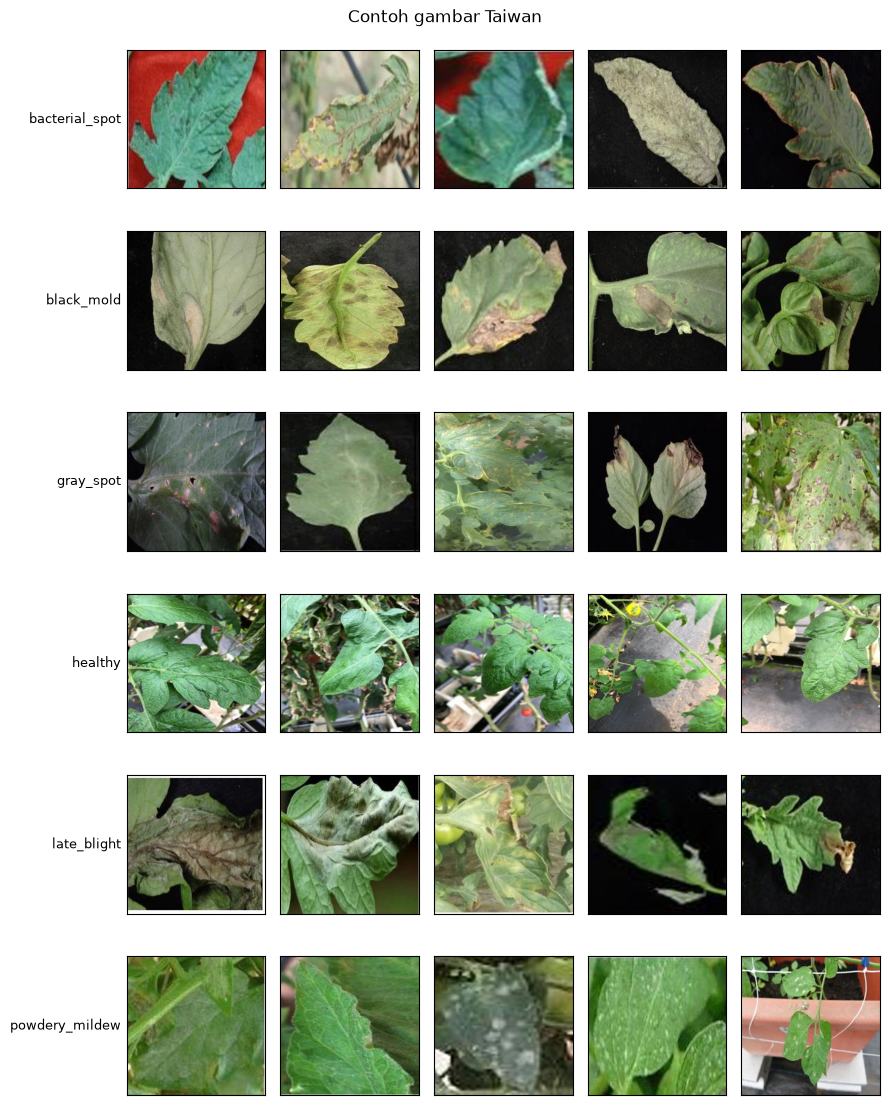

In [5]:
def sample_grid(df, name, n=5):
    labels = sorted(df.label.unique())
    fig, axes = plt.subplots(len(labels), n, figsize=(n * 1.8, len(labels) * 1.9))
    for r, lbl in enumerate(labels):
        paths = df[df.label == lbl].sample(n, random_state=SEED).path
        for c, p in enumerate(paths):
            ax = axes[r, c]
            ax.imshow(Image.open(DATASET_DIR / p).convert("RGB"))
            ax.set_xticks([]); ax.set_yticks([])
            if c == 0:
                ax.set_ylabel(lbl, rotation=0, ha="right", va="center", fontsize=9)
    fig.suptitle(f"Contoh gambar {name}")
    fig.tight_layout()
    fig.savefig(EDA_DIR / f"contoh_{name.lower()}.png", dpi=120, bbox_inches="tight")
    plt.show()

sample_grid(pv, "PlantVillage")
sample_grid(tw, "Taiwan")

## Statistik citra: ukuran dan warna

Membandingkan kecerahan dan rata-rata warna kedua dataset. Perbedaan besar di sini adalah tanda *domain shift*
(foto lab vs foto lapangan) yang membuat model dari PlantVillage sulit dipakai di Taiwan.

PlantVillage | ukuran: {'227x227': 600} | mode: {'RGB': 600}
Taiwan | ukuran: {'227x227': 360} | mode: {'RGB': 360}


,PlantVillage,Taiwan
R,0.453,0.410
G,0.463,0.472
B,0.421,0.337
brightness,0.446,0.406
contrast,0.165,0.218


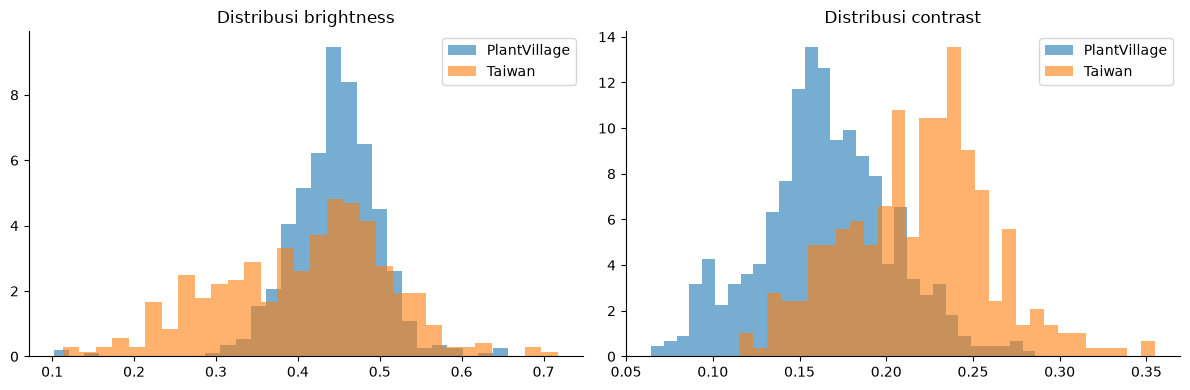

In [6]:
def image_stats(df, n_per_class=60):
    rows = []
    for lbl, g in df.groupby("label"):
        for p in g.sample(min(n_per_class, len(g)), random_state=SEED).path:
            img = Image.open(DATASET_DIR / p)
            arr = np.asarray(img.convert("RGB"), dtype=np.float32) / 255
            rows.append({"label": lbl, "size": f"{img.width}x{img.height}", "mode": img.mode,
                         "R": arr[..., 0].mean(), "G": arr[..., 1].mean(), "B": arr[..., 2].mean(),
                         "brightness": arr.mean(), "contrast": arr.std()})
    return pd.DataFrame(rows)

pv_stats, tw_stats = image_stats(pv), image_stats(tw)
for name, s in (("PlantVillage", pv_stats), ("Taiwan", tw_stats)):
    print(name, "| ukuran:", s["size"].value_counts().to_dict(), "| mode:", s["mode"].value_counts().to_dict())

summary = pd.DataFrame({"PlantVillage": pv_stats[["R", "G", "B", "brightness", "contrast"]].mean(),
                        "Taiwan": tw_stats[["R", "G", "B", "brightness", "contrast"]].mean()}).round(3)
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for col, ax in zip(("brightness", "contrast"), axes):
    ax.hist(pv_stats[col], bins=30, alpha=0.6, density=True, label="PlantVillage")
    ax.hist(tw_stats[col], bins=30, alpha=0.6, density=True, label="Taiwan")
    ax.set_title(f"Distribusi {col}")
    ax.legend()
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(EDA_DIR / "statistik_citra.png", dpi=150, bbox_inches="tight")
plt.show()

## 3f. Temuan penting yang memengaruhi preprocessing

| Temuan | Dampak ke preprocessing |
|---|---|
| Semua gambar sudah 227x227 RGB, tidak ada file rusak | Cukup resize ke 224x224 dan normalisasi sesuai ImageNet (model pretrained) |
| PlantVillage: 10 pasang gambar identik (5 `healthy`, 5 `late_blight`) | Duplikat dibuang sebelum split agar tidak bocor ke test (`make_splits.py`) |
| PlantVillage tidak seimbang (`yellow_leaf_curl_virus` ~14x `mosaic_virus`) | Pakai class weight / focal loss dan laporkan F1 per kelas, bukan hanya akurasi |
| Folder `data augmentation` Taiwan: 100% gambar test berasal dari daun yang ada di train | Folder itu tidak dipakai; augmentasi dilakukan saat training, hanya pada data train |
| PlantVillage foto lab (latar polos), Taiwan foto lapangan (latar ramai) | Augmentasi warna/crop untuk ketahanan; uji silang PlantVillage -> Taiwan untuk mengukur *domain shift* |
| Taiwan: latar foto berkorelasi dengan kelas (pada sampel: `healthy` berupa foto lapangan, `black_mold`/`gray_spot` dominan berlatar hitam) | Risiko *shortcut learning*: model bisa menebak dari latar. Dicek dengan Grad-CAM (fitur unik 1) dan augmentasi crop/warna |
| PlantVillage: sebagian kecil gambar sudah disegmentasi (latar hitam) | Tidak dibuang; ikut menambah variasi latar |
| Hanya 3 kelas yang sama di kedua dataset | Uji silang hanya pada `bacterial_spot`, `late_blight`, `healthy` |
| Taiwan kecil (622 gambar asli) | Transfer learning + fine-tuning, bukan training dari nol |